#### Part 2: text generation with GPT-2

we fine-tune a pretrained GPT-2 on our own dataset (the arabic articles about artificial intelligence that we scraped in part 1), then we give it a sentence and it writes the next words.

- `pytorch-transformers` is the old name of the library, today it is called `transformers` (`pip install transformers`), same code
- the original GPT-2 only knows english, so we use **AraGPT2** (`aubmindlab/aragpt2-base`): it is a GPT-2 model (same architecture) pretrained on arabic text
- following the tutorial: a dataset class, a training loop with AdamW and a learning rate scheduler, then generation with top-k / top-p sampling
- to measure the effect of the fine-tuning we compare the model before and after with the **perplexity** (lower is better) and the **BLEU** score

In [1]:
# pip install transformers

import time
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForCausalLM, get_linear_schedule_with_warmup

random.seed(0)
np.random.seed(0)
torch.manual_seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Selected device:", device)

Selected device: cuda


##### load the pretrained model

we load it twice: `base_model` stays as it is (to compare), `model` is the one we fine-tune

In [2]:
model_name = "aubmindlab/aragpt2-base"

tokenizer = AutoTokenizer.from_pretrained(model_name)
tokenizer.pad_token = tokenizer.eos_token     # gpt-2 has no padding token

base_model = AutoModelForCausalLM.from_pretrained(model_name).to(device)

# the model we fine-tune: we switch off the dropout. with dropout 0.1 the loss of this pretrained model
# jumps from 6.2 to 10.6 (we measured it on a batch), so it would first have to repair itself before learning from our articles
model = AutoModelForCausalLM.from_pretrained(model_name, resid_pdrop=0.0, embd_pdrop=0.0, attn_pdrop=0.0).to(device)

n_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"{n_params:.0f} M parameters")

[transformers] GPT2LMHeadModel LOAD REPORT from: aubmindlab/aragpt2-base
Key                         | Status     |  | 
----------------------------+------------+--+-
h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[transformers] GPT2LMHeadModel LOAD REPORT from: aubmindlab/aragpt2-base
Key                         | Status     |  | 
----------------------------+------------+--+-
h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


135 M parameters


##### our dataset

we keep the articles with a medium or high relevance to artificial intelligence (label 1 and 2 of part 1). each sample is the title, a new line, and the beginning of the article (256 tokens at most), followed by the end-of-text token

In [3]:
df = pd.read_csv("../dataset/arabic_texts_scored.csv")
df = df[df["label"] >= 1].reset_index(drop=True)
df["sample"] = df["title"] + "\n" + df["text"]
print(len(df), "articles")

train_df = df.sample(frac=0.9, random_state=0)
val_df = df.drop(train_df.index)
print(len(train_df), "for training,", len(val_df), "for validation")

MAX_LEN = 256

class ArticleDataset(Dataset):
    def __init__(self, texts):
        self.items = []
        for text in texts:
            ids = tokenizer(text, truncation=True, max_length=MAX_LEN - 1)["input_ids"]
            self.items.append(ids + [tokenizer.eos_token_id])

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        return self.items[i]

def collate(batch):
    # pad all the samples of the batch to the same length
    longest = max(len(ids) for ids in batch)
    input_ids = torch.full((len(batch), longest), tokenizer.pad_token_id)
    attention_mask = torch.zeros((len(batch), longest), dtype=torch.long)
    labels = torch.full((len(batch), longest), -100)      # -100 = ignored by the loss
    for i, ids in enumerate(batch):
        input_ids[i, :len(ids)] = torch.tensor(ids)
        attention_mask[i, :len(ids)] = 1
        labels[i, :len(ids)] = torch.tensor(ids)
    return input_ids, attention_mask, labels

train_loader = DataLoader(ArticleDataset(train_df["sample"]), batch_size=8, shuffle=True, collate_fn=collate)
val_loader = DataLoader(ArticleDataset(val_df["sample"]), batch_size=16, collate_fn=collate)

# one sample
print(train_df["sample"].iloc[0][:200])

1686 articles
1517 for training, 169 for validation
جوجل تطلق تطبيقها الجديد لنظام ويندوز بقدرات بحث وذكاء اصطناعي مُدمجة
أعلنت جوجل إتاحة تطبيقها الجديد لأجهزة الحاسوب العاملة بنظام ويندوز عالميًا باللغة الإنجليزية بعد مُدة من الاختبارات، لتتيح بذلك ت


##### perplexity

the perplexity says how surprised the model is by the real articles of the validation set. lower is better

In [4]:
use_fp16 = device.type == "cuda"     # half precision is faster on the gpu

def perplexity(m, loader):
    m.eval()
    total_loss, total_tokens = 0.0, 0
    with torch.no_grad():
        for input_ids, attention_mask, labels in loader:
            input_ids, attention_mask, labels = input_ids.to(device), attention_mask.to(device), labels.to(device)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_fp16):
                loss = m(input_ids=input_ids, attention_mask=attention_mask, labels=labels).loss
            n_tokens = (labels[:, 1:] != -100).sum().item()
            total_loss += loss.item() * n_tokens
            total_tokens += n_tokens
    return math.exp(total_loss / total_tokens)

ppl_before = perplexity(base_model, val_loader)
print("perplexity before fine-tuning:", round(ppl_before, 2))

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


perplexity before fine-tuning: 318.01


##### generation

we give a sentence (the prompt) and the model continues it. we use sampling with top-k and top-p, and we forbid to repeat the same 3 words, so the text is more varied

In [5]:
def generate(m, prompt, max_new_tokens=100):
    inputs = tokenizer(prompt, return_tensors="pt").to(device)
    output = m.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=True,
        top_k=50,
        top_p=0.95,
        temperature=0.8,
        no_repeat_ngram_size=3,
        pad_token_id=tokenizer.eos_token_id,
    )
    return tokenizer.decode(output[0], skip_special_tokens=True)

prompts = [
    "أعلنت شركة جوجل عن نموذج جديد للذكاء الاصطناعي",
    "الذكاء الاصطناعي سيغير مستقبل التعليم",
    "أطلقت أوبن إيه آي نسخة جديدة من ChatGPT",
    "تتسابق الشركات الكبرى لتطوير الروبوتات",
]

# before fine-tuning
for prompt in prompts:
    torch.manual_seed(0)
    print("PROMPT:", prompt)
    print(generate(base_model, prompt))
    print("-" * 80)

PROMPT: أعلنت شركة جوجل عن نموذج جديد للذكاء الاصطناعي
أعلنت شركة جوجل عن نموذج جديد للذكاء الاصطناعي يحمل اسم Pew . هذه النسخة الجديدة من الذكاء الاصطناعي توفر للمستخدمين فرصة أكبر للعثور على المعلومات عن الأماكن والأشياء التي يمكن رؤيتها من خلال الصور الفوتوغرافية .تتيح النسخة الجديدة هذه للمستخدمين إمكانية إجراء الصور الفوتوغرافية أو مشاهدة المواقع التي تم التقاطها باستخدام كاميرا غوغل أو كاميرات الويب .تعمل غوغل على تصميم هواتف بيكسل التي تحمل اسم P - Pen ، لكن في الوقت الذي تسعى فيه غوغل إلى إنشاء هواتف بيكسل من خلال تزويدها بكاميرا للتصوير ، فإن هاتف بيكسل بي يعمل من خلال استخدام الكاميرا في الصور الفوتوغرافية الرقمية ، كما
--------------------------------------------------------------------------------
PROMPT: الذكاء الاصطناعي سيغير مستقبل التعليم
الذكاء الاصطناعي سيغير مستقبل التعليم العالي في العالم ، لا سيما مع وجود فرص أكبر للتعليم العالي في إفريقيا ، إذ إنه سيعزز الابتكار في تكنولوجيا التعليم العالي .وسيكون لهذه التطورات تأثير على القطاع ، كما ستعزز من فرص التعليم العالي بش

##### fine-tuning

the loss of a language model is the cross-entropy on the next word. we use AdamW, a small learning rate (5e-5), a warm-up (the learning rate grows during the first 10% of the steps, then decreases) and gradient clipping

In [6]:
epochs = 3
lr = 5e-5

optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
total_steps = epochs * len(train_loader)
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=int(0.1 * total_steps), num_training_steps=total_steps)
scaler = torch.amp.GradScaler("cuda", enabled=use_fp16)

train_losses, val_ppls = [], []

t0 = time.time()
for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for input_ids, attention_mask, labels in train_loader:
        input_ids, attention_mask, labels = input_ids.to(device), attention_mask.to(device), labels.to(device)

        optimizer.zero_grad()
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_fp16):
            loss = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels).loss

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        running_loss += loss.item() * len(input_ids)

    train_losses.append(running_loss / len(train_df))
    val_ppls.append(perplexity(model, val_loader))
    print(f"Epoch {epoch + 1}/{epochs} | Train loss: {train_losses[-1]:.4f} | Validation perplexity: {val_ppls[-1]:.2f}")

train_time = time.time() - t0
print(f"Training time: {train_time:.1f} s")

Epoch 1/3 | Train loss: 3.8217 | Validation perplexity: 28.31
Epoch 2/3 | Train loss: 2.9577 | Validation perplexity: 25.63
Epoch 3/3 | Train loss: 2.5915 | Validation perplexity: 27.30
Training time: 155.8 s


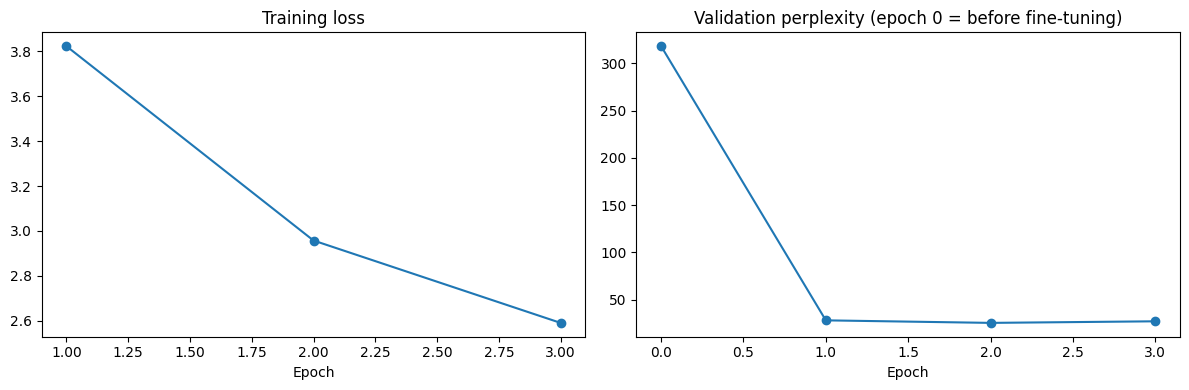

In [7]:
import os
os.makedirs("../figures", exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, epochs + 1), train_losses, marker="o")
axes[0].set_title("Training loss")
axes[0].set_xlabel("Epoch")
axes[1].plot(range(0, epochs + 1), [ppl_before] + val_ppls, marker="o")
axes[1].set_title("Validation perplexity (epoch 0 = before fine-tuning)")
axes[1].set_xlabel("Epoch")
plt.tight_layout()
plt.savefig("../figures/gpt2_training.png", dpi=120, bbox_inches="tight")
plt.show()

##### generation after fine-tuning

same prompts, same random seed as before

In [8]:
for prompt in prompts:
    torch.manual_seed(0)
    print("PROMPT:", prompt)
    print(generate(model, prompt))
    print("-" * 80)

PROMPT: أعلنت شركة جوجل عن نموذج جديد للذكاء الاصطناعي
أعلنت شركة جوجل عن نموذج جديد للذكاء الاصطناعي يحمل اسم Gemini 4، وذلك خلال مؤتمر Google I/O 2026. مُشتركة بين Google I�اني و Sora، كما أعلنت الشركة عن إطلاق نسخة مدعومة بالذكاء الاصطناعي من المساعد الذكي Sora.  وتأتي هذه الخطوة في إطار خطط الشركة لطرح أدوات جديدة للذكاء الصناعي، مع توسيع نطاق استخدام هذه الأدوات لتشمل هواتف أندرويد، خاصةً مع الاعتماد المتزايد على أنظمة التشغيل نفسها. ويعتمد النموذج الجديد على نموذج Gemi AI 4 الذي
--------------------------------------------------------------------------------
PROMPT: الذكاء الاصطناعي سيغير مستقبل التعليم
الذكاء الاصطناعي سيغير مستقبل التعليم في بريطانيا، وشهادات من جامعات سعودية، وهيئات طلابية، ومبادرات فردية، واستقرارًا نفسيًيقدم موقع “ذا فيرج “ (Firstward) الأمريكي مجموعة من الوظائف والوظائف التي يقدمها الذكاء الاصطناعي داخل المؤسسات التعليمية، وفقًاها. ومن أبرزها، الوظيفة التي يقدمها “جيف بيزوس”، وكيل ذكاء اصطناعي معتمد، وقد عمل سابقا في معهد لندن للاقتصاد الدولي، وهو المسؤول ع

##### BLEU score

BLEU compares a generated text with a reference text (the words they have in common). for each article of the validation set, the prompt is its first 25 words, the reference is the next 50 words, and the model writes 80 new tokens (without sampling, so the result is always the same). a generated text can be good and still different from the reference, so the values are low, we use BLEU to compare the model before and after the fine-tuning

In [9]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

N_BLEU = 50

def bleu_score(m):
    references, hypotheses = [], []
    for text in val_df["text"].iloc[:N_BLEU]:
        words = text.split()
        prompt = " ".join(words[:25])
        reference = words[25:75]

        inputs = tokenizer(prompt, return_tensors="pt").to(device)
        output = m.generate(**inputs, max_new_tokens=80, do_sample=False, no_repeat_ngram_size=3,
                            pad_token_id=tokenizer.eos_token_id)
        generated = tokenizer.decode(output[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)

        references.append([reference])
        hypotheses.append(generated.split()[:50])

    return corpus_bleu(references, hypotheses, smoothing_function=SmoothingFunction().method1)

bleu_before = bleu_score(base_model)
bleu_after = bleu_score(model)
print("BLEU before:", round(bleu_before, 4), "| after:", round(bleu_after, 4))

BLEU before: 0.0048 | after: 0.0131


In [10]:
ppl_after = perplexity(model, val_loader)

table = pd.DataFrame({
    "Perplexity": [ppl_before, ppl_after],
    "BLEU": [bleu_before, bleu_after],
}, index=["AraGPT2 (before)", "AraGPT2 (fine-tuned)"]).round(4)
display(table)
print(f"Training time: {train_time:.1f} s | {epochs} epochs | {len(train_df)} training articles | {n_params:.0f} M parameters")

,Perplexity,BLEU
AraGPT2 (before),318.0134,0.0048
AraGPT2 (fine-tuned),27.3006,0.0131


Training time: 155.8 s | 3 epochs | 1517 training articles | 135 M parameters


#### Conclusion:

The fine-tuning clearly works: the perplexity on the validation articles goes from **318 to 27.3** and the BLEU score from 0.0048 to 0.0131 (very low in absolute value, because a good continuation rarely uses the same words as the reference, but it is almost 3 times higher). The validation perplexity was 28.3, 25.6 and 27.3 after the three epochs, so the third epoch starts to overfit and 2 epochs would have been a little better.

The generated texts changed a lot. Before, the model wrote old-style text without any link to the prompt (Android 4.4, Symbian, old phones). After, it writes in the style of a modern tech news site and uses the right vocabulary (Gemini, Google I/O 2026, AI assistants, robots).

But the model does not know facts, it only copies the style. It says for example that OpenAI belongs to Elon Musk, it invents names and numbers, and it sometimes mixes unrelated subjects in one paragraph. A few characters are also broken, because the tokenizer works on bytes and sometimes cuts an Arabic letter in the middle. So the text sounds right but cannot be trusted, and it needs a human to check it.

One thing we learned the hard way: with the default dropout (0.1) the loss of this pretrained model was 10.6 instead of 6.2 on the same batch, so we switched the dropout off for the fine-tuning. We also had to use an Arabic GPT-2 (AraGPT2): the original English GPT-2 does not know Arabic.